<h2>Checking whether raw data exists</h2>

In [ ]:
from pathlib import Path
import pandas as pd 
import numpy as np

In [ ]:
#Project Data Folder
DATA_DIR = Path("../data/raw/stock_prices")

In [ ]:
#Stock files to inspect
stocks = ["AAPL","MSFT","NVDA","AMZN","GOOGL"]

In [ ]:
print("Libraries imported successfully!")
print("Data folder:", DATA_DIR.resolve())
print("Folder exists:", DATA_DIR.exists())

Libraries imported successfully!
Data folder: C:\My Data\Codes\Data Analysis\Financial_Market_Intelligence\data\raw\stock_prices
Folder exists: True


<h2> Loading all five stocks CSV Files</h2>

In [ ]:

stock_data = {}

for ticker in stocks:
    file_path = DATA_DIR / f"{ticker}.csv.csv"
    
    stock_data[ticker] = pd.read_csv(file_path)
    
    print(
        f"{ticker}: {stock_data[ticker].shape[0]} rows, "
        f"{stock_data[ticker].shape[1]} columns"
    )

print("\nAll five stock files loaded successfully!")


AAPL: 2513 rows, 6 columns
MSFT: 2513 rows, 6 columns
NVDA: 2513 rows, 6 columns
AMZN: 2513 rows, 6 columns
GOOGL: 2513 rows, 6 columns

All five stock files loaded successfully!


<h2>Inspecting the Data Quality</h2>

In [ ]:
for ticker, df in stock_data.items():
    print(f"\n{'=' * 45}")
    print(f"STOCK: {ticker}")
    print('=' * 45)
    
    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values per column:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nFirst & Last rows:")
    display(df.head(1))
    display(df.tail(1))


STOCK: AAPL

Column names:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume']

Data types:
Date       object
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object

Missing values per column:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Duplicate rows: 0

First & Last rows:


,Date,Open,High,Low,Close,Volume
0,10/21/2016 16:00:00,29.2,29.23,29.07,29.15,23192665


,Date,Open,High,Low,Close,Volume
2512,10/21/2026 16:00:00,339.36,345.25,338.83,343.99,35614127



STOCK: MSFT

Column names:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume']

Data types:
Date       object
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object

Missing values per column:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Duplicate rows: 0

First & Last rows:


,Date,Open,High,Low,Close,Volume
0,10/21/2016 16:00:00,60.28,60.45,59.49,59.66,80032206


...

,Date,Open,High,Low,Close,Volume
0,10/21/2016 16:00:00,40.47,40.97,40.45,40.95,2793015


,Date,Open,High,Low,Close,Volume
2512,10/21/2026 16:00:00,262.71,264.36,259.29,262.37,31214698



STOCK: GOOGL

Column names:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume']

Data types:
Date       object
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object

Missing values per column:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Duplicate rows: 0

First & Last rows:


,Date,Open,High,Low,Close,Volume
0,10/21/2016 16:00:00,41.0,41.21,40.92,41.2,1615814


,Date,Open,High,Low,Close,Volume
2512,10/21/2026 16:00:00,336.98,337.27,330.38,334.76,29165541


<h2>Converting dates</h2>

In [ ]:

for ticker, df in stock_data.items():
    # Convert Date from text to actual datetime
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    # Convert price and volume columns to numeric values
    numeric_columns = ["Open", "High", "Low", "Close", "Volume"]

    for col in numeric_columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Sort from oldest date to newest date
    df.sort_values("Date", inplace=True)
    df.reset_index(drop=True, inplace=True)

    print(f"\n{ticker}")
    print("Date type:", df["Date"].dtype)
    print("Date range:", df["Date"].min(), "to", df["Date"].max())
    print("Missing dates:", df["Date"].isna().sum())
    print("Missing numeric values:", df[numeric_columns].isna().sum().sum())
    print("Duplicate dates:", df["Date"].duplicated().sum())



AAPL
Date type: datetime64[ns]
Date range: 2016-10-21 16:00:00 to 2026-10-21 16:00:00
Missing dates: 0
Missing numeric values: 0
Duplicate dates: 0

MSFT
Date type: datetime64[ns]
Date range: 2016-10-21 16:00:00 to 2026-10-21 16:00:00
Missing dates: 0
Missing numeric values: 0
Duplicate dates: 0

NVDA
Date type: datetime64[ns]
Date range: 2016-10-21 16:00:00 to 2026-10-21 16:00:00
Missing dates: 0
Missing numeric values: 0
Duplicate dates: 0

AMZN
Date type: datetime64[ns]
Date range: 2016-10-21 16:00:00 to 2026-10-21 16:00:00
Missing dates: 0
Missing numeric values: 0
Duplicate dates: 0

GOOGL
Date type: datetime64[ns]
Date range: 2016-10-21 16:00:00 to 2026-10-21 16:00:00
Missing dates: 0
Missing numeric values: 0
Duplicate dates: 0


<h2>Validating price data</h2>

In [ ]:

for ticker, df in stock_data.items():
    print(f"\n{'=' * 35}")
    print(f"VALIDATION: {ticker}")
    print("=" * 35)

    # Check whether prices are positive
    invalid_prices = (
        (df[["Open", "High", "Low", "Close"]] <= 0).any(axis=1)
    )

    # High should be at least as large as Open, Low, and Close
    invalid_high = (
        df["High"] < df[["Open", "Low", "Close"]].max(axis=1)
    )

    # Low should be no greater than Open, High, and Close
    invalid_low = (
        df["Low"] > df[["Open", "High", "Close"]].min(axis=1)
    )

    # Volume should not be negative
    invalid_volume = df["Volume"] < 0

    print("Non-positive prices:", invalid_prices.sum())
    print("Invalid High values:", invalid_high.sum())
    print("Invalid Low values:", invalid_low.sum())
    print("Negative Volume values:", invalid_volume.sum())



VALIDATION: AAPL
Non-positive prices: 0
Invalid High values: 0
Invalid Low values: 0
Negative Volume values: 0

VALIDATION: MSFT
Non-positive prices: 0
Invalid High values: 0
Invalid Low values: 0
Negative Volume values: 0

VALIDATION: NVDA
Non-positive prices: 0
Invalid High values: 0
Invalid Low values: 0
Negative Volume values: 0

VALIDATION: AMZN
Non-positive prices: 0
Invalid High values: 0
Invalid Low values: 0
Negative Volume values: 0

VALIDATION: GOOGL
Non-positive prices: 0
Invalid High values: 0
Invalid Low values: 0
Negative Volume values: 0


<h2>Calculating Daily Stock Return Percentage</h2>

In [ ]:

for ticker, df in stock_data.items():
    # Calculate daily percentage return
    df["Daily_Return"] = df["Close"].pct_change()

    print(f"\n{ticker}")
    display(
    df[["Date", "Close", "Daily_Return"]]
    .head(5)
    .style.format({"Daily_Return": "{:.2%}"})
)



AAPL


,Date,Close,Daily_Return
0,2016-10-21 16:00:00,29.150000,nan%
1,2016-10-24 16:00:00,29.410000,0.89%
2,2016-10-25 16:00:00,29.560000,0.51%
3,2016-10-26 16:00:00,28.900000,-2.23%
4,2016-10-27 16:00:00,28.620000,-0.97%



MSFT


,Date,Close,Daily_Return
0,2016-10-21 16:00:00,59.660000,nan%
1,2016-10-24 16:00:00,61.000000,2.25%
2,2016-10-25 16:00:00,60.990000,-0.02%
3,2016-10-26 16:00:00,60.630000,-0.59%
4,2016-10-27 16:00:00,60.100000,-0.87%



NVDA


,Date,Close,Daily_Return
0,2016-10-21 16:00:00,1.690000,nan%
1,2016-10-24 16:00:00,1.770000,4.73%
2,2016-10-25 16:00:00,1.800000,1.69%
3,2016-10-26 16:00:00,1.800000,0.00%
4,2016-10-27 16:00:00,1.770000,-1.67%



AMZN


,Date,Close,Daily_Return
0,2016-10-21 16:00:00,40.950000,nan%
1,2016-10-24 16:00:00,41.900000,2.32%
2,2016-10-25 16:00:00,41.760000,-0.33%
3,2016-10-26 16:00:00,41.130000,-1.51%
4,2016-10-27 16:00:00,40.920000,-0.51%



GOOGL


,Date,Close,Daily_Return
0,2016-10-21 16:00:00,41.200000,nan%
1,2016-10-24 16:00:00,41.790000,1.43%
2,2016-10-25 16:00:00,41.430000,-0.86%
3,2016-10-26 16:00:00,41.110000,-0.77%
4,2016-10-27 16:00:00,40.870000,-0.58%


<h2>Calculating Cumulative Returns</h2>

In [ ]:

for ticker, df in stock_data.items():
    df["Cumulative_Return"] = (
        (1 + df["Daily_Return"]).cumprod() - 1
    )

    print(f"\n{ticker}")
    display(
        df[["Date", "Close", "Daily_Return", "Cumulative_Return"]]
        .tail(5)
        .style.format({
            "Close": "${:,.2f}",
            "Daily_Return": "{:.2%}",
            "Cumulative_Return": "{:.2%}"
        })
    )



AAPL


,Date,Close,Daily_Return,Cumulative_Return
2508,2026-10-15 16:00:00,$342.00,-0.28%,1073.24%
2509,2026-10-16 16:00:00,$343.46,0.43%,1078.25%
2510,2026-10-19 16:00:00,$342.94,-0.15%,1076.47%
2511,2026-10-20 16:00:00,$339.50,-1.00%,1064.67%
2512,2026-10-21 16:00:00,$343.99,1.32%,1080.07%



MSFT


,Date,Close,Daily_Return,Cumulative_Return
2508,2026-10-15 16:00:00,$539.44,1.08%,804.19%
2509,2026-10-16 16:00:00,$529.05,-1.93%,786.78%
2510,2026-10-19 16:00:00,$533.52,0.84%,794.27%
2511,2026-10-20 16:00:00,$531.87,-0.31%,791.50%
2512,2026-10-21 16:00:00,$532.95,0.20%,793.31%



NVDA


,Date,Close,Daily_Return,Cumulative_Return
2508,2026-10-15 16:00:00,$217.23,-1.84%,12753.85%
2509,2026-10-16 16:00:00,$214.13,-1.43%,12570.41%
2510,2026-10-19 16:00:00,$217.09,1.38%,12745.56%
2511,2026-10-20 16:00:00,$216.47,-0.29%,12708.88%
2512,2026-10-21 16:00:00,$221.97,2.54%,13034.32%



AMZN


,Date,Close,Daily_Return,Cumulative_Return
2508,2026-10-15 16:00:00,$254.76,0.27%,522.12%
2509,2026-10-16 16:00:00,$250.00,-1.87%,510.50%
2510,2026-10-19 16:00:00,$262.45,4.98%,540.90%
2511,2026-10-20 16:00:00,$262.63,0.07%,541.34%
2512,2026-10-21 16:00:00,$262.37,-0.10%,540.71%



GOOGL


,Date,Close,Daily_Return,Cumulative_Return
2508,2026-10-15 16:00:00,$349.22,0.45%,747.62%
2509,2026-10-16 16:00:00,$340.59,-2.47%,726.67%
2510,2026-10-19 16:00:00,$344.18,1.05%,735.39%
2511,2026-10-20 16:00:00,$340.28,-1.13%,725.92%
2512,2026-10-21 16:00:00,$334.76,-1.62%,712.52%


<h2>Ploting Cumulative Returns using Matplotlib</h2>

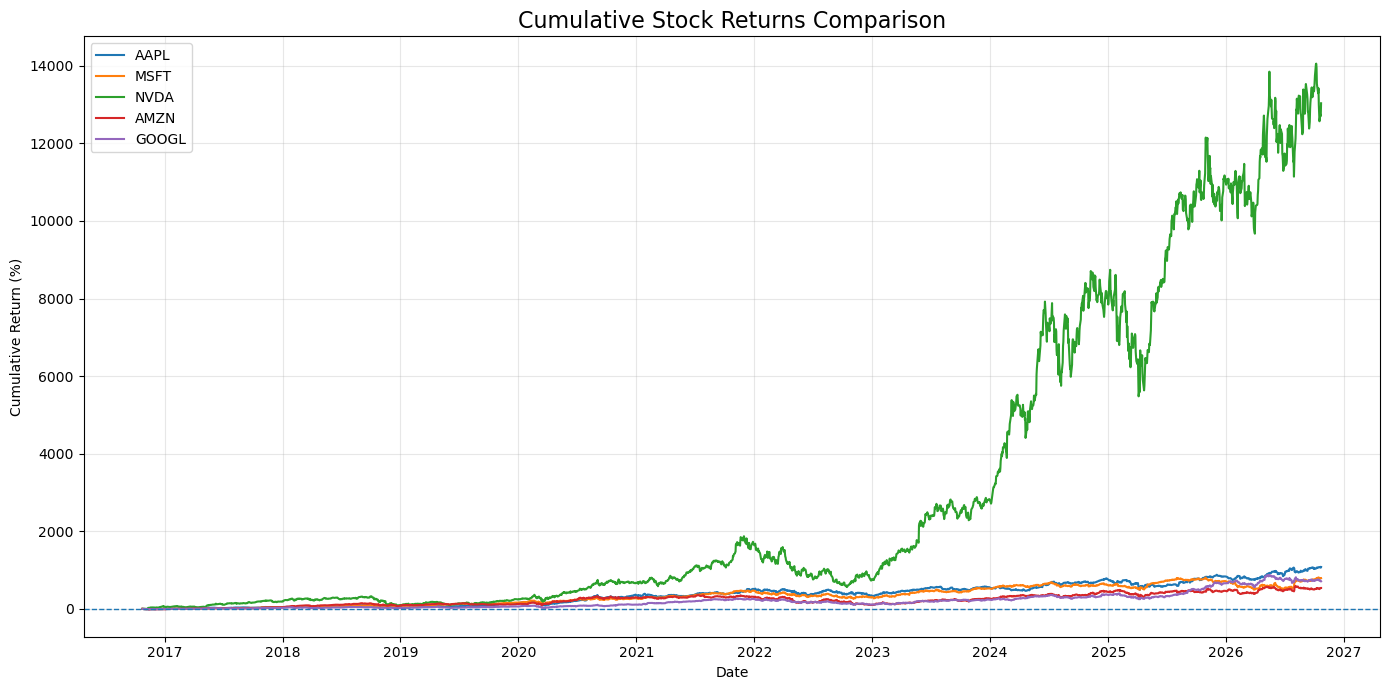

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14,7))

for ticker, df in stock_data.items():
    plt.plot(
        df["Date"],
        df["Cumulative_Return"] * 100,
        label=ticker
    )

plt.title("Cumulative Stock Returns Comparison", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Cumulative Return (%)")
plt.axhline(y=0, linestyle="--", linewidth=1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<h3>As we see here, Nvidia Stock Price. Let's focus on it and check the return calculation</h3>

In [ ]:

nvda = stock_data["NVDA"]

print("First observation:")
display(
        nvda[["Date", "Close", "Daily_Return", "Cumulative_Return"]]
        .head(5)
        .style.format({
            "Close": "${:,.2f}",
            "Daily_Return": "{:.2%}",
            "Cumulative_Return": "{:.2%}"
        })
    )

print("\nLast observation:")
display(
        nvda[["Date", "Close", "Daily_Return", "Cumulative_Return"]]
        .tail(5)
        .style.format({
            "Close": "${:,.2f}",
            "Daily_Return": "{:.2%}",
            "Cumulative_Return": "{:.2%}"
        })
    )
print("First closing price:", nvda["Close"].iloc[0])
print("Last closing price:", nvda["Close"].iloc[-1])
print("\nCalculated cumulative return:")
print(f"{nvda['Cumulative_Return'].iloc[-1]:.2%}")


First observation:


,Date,Close,Daily_Return,Cumulative_Return
0,2016-10-21 16:00:00,$1.69,nan%,nan%
1,2016-10-24 16:00:00,$1.77,4.73%,4.73%
2,2016-10-25 16:00:00,$1.80,1.69%,6.51%
3,2016-10-26 16:00:00,$1.80,0.00%,6.51%
4,2016-10-27 16:00:00,$1.77,-1.67%,4.73%



Last observation:


,Date,Close,Daily_Return,Cumulative_Return
2508,2026-10-15 16:00:00,$217.23,-1.84%,12753.85%
2509,2026-10-16 16:00:00,$214.13,-1.43%,12570.41%
2510,2026-10-19 16:00:00,$217.09,1.38%,12745.56%
2511,2026-10-20 16:00:00,$216.47,-0.29%,12708.88%
2512,2026-10-21 16:00:00,$221.97,2.54%,13034.32%


First closing price: 1.69
Last closing price: 221.97

Calculated cumulative return:
13034.32%


<h3>Similarly, analysis the price range & cumulative return of all 5 stocks</h3>

In [ ]:

for ticker, df in stock_data.items():
    first_price = df["Close"].iloc[0]
    last_price = df["Close"].iloc[-1]
    cumulative_return = df["Cumulative_Return"].iloc[-1]

    print(
        f"{ticker:5} | "
        f"Start: ${first_price:8.2f} | "
        f"End: ${last_price:8.2f} | "
        f"Cumulative return: {cumulative_return:10.2%}"
    )


AAPL  | Start: $   29.15 | End: $  343.99 | Cumulative return:   1080.07%
MSFT  | Start: $   59.66 | End: $  532.95 | Cumulative return:    793.31%
NVDA  | Start: $    1.69 | End: $  221.97 | Cumulative return:  13034.32%
AMZN  | Start: $   40.95 | End: $  262.37 | Cumulative return:    540.71%
GOOGL | Start: $   41.20 | End: $  334.76 | Cumulative return:    712.52%


<h2>Calculating Avg Daily Return & Daily/Annualized Volatility</h2>

In [ ]:

risk_summary = []

for ticker, df in stock_data.items():
    returns = df["Daily_Return"].dropna()

    risk_summary.append({
        "Ticker": ticker,
        "Average Daily Return (%)": returns.mean() * 100,
        "Daily Volatility (%)": returns.std() * 100,
        "Annualized Volatility (%)": returns.std() * np.sqrt(252) * 100
    })

risk_summary_df = pd.DataFrame(risk_summary)

display(
    risk_summary_df.style.format({
        "Average Daily Return (%)": "{:.4f}%",
        "Daily Volatility (%)": "{:.4f}%",
        "Annualized Volatility (%)": "{:.2f}%"
    })
)


,Ticker,Average Daily Return (%),Daily Volatility (%),Annualized Volatility (%)
0,AAPL,0.1151%,1.8366%,29.16%
1,MSFT,0.1025%,1.7497%,27.78%
2,NVDA,0.2437%,3.1560%,50.10%
3,AMZN,0.0957%,2.0914%,33.20%
4,GOOGL,0.1009%,1.8685%,29.66%


<h2>Final Check on Data Cleaning</h2>

In [ ]:

for ticker, df in stock_data.items():
    print(f"\n{'=' * 40}")
    print(f"FINAL CLEANING CHECK: {ticker}")
    print("=" * 40)

    # Check missing values
    print("Missing values:")
    print(df[["Date", "Open", "High", "Low", "Close", "Volume"]]
          .isna().sum())

    # Check duplicate dates
    print("Duplicate dates:", df["Date"].duplicated().sum())

    # Check whether dates are sorted
    print("Dates sorted:", df["Date"].is_monotonic_increasing)

    # Check for invalid price relationships
    invalid_ohlc = (
        (df["High"] < df[["Open", "Low", "Close"]].max(axis=1))
        | (df["Low"] > df[["Open", "High", "Close"]].min(axis=1))
    )
    print("Invalid OHLC rows:", invalid_ohlc.sum())

    # Check negative volume
    print("Negative volume rows:", (df["Volume"] < 0).sum())



FINAL CLEANING CHECK: AAPL
Missing values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Duplicate dates: 0
Dates sorted: True
Invalid OHLC rows: 0
Negative volume rows: 0

FINAL CLEANING CHECK: MSFT
Missing values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Duplicate dates: 0
Dates sorted: True
Invalid OHLC rows: 0
Negative volume rows: 0

FINAL CLEANING CHECK: NVDA
Missing values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Duplicate dates: 0
Dates sorted: True
Invalid OHLC rows: 0
Negative volume rows: 0

FINAL CLEANING CHECK: AMZN
Missing values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Duplicate dates: 0
Dates sorted: True
Invalid OHLC rows: 0
Negative volume rows: 0

FINAL CLEANING CHECK: GOOGL
Missing values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Duplicate dates: 0
Dat

<h2>Combining all 5 Stocks into 1 Table</h2>

In [ ]:

# Combine all five stock DataFrames into one table
master_df = pd.concat(
    [
        df.assign(Ticker=ticker)
        for ticker, df in stock_data.items()
    ],
    ignore_index=True
)

# Arrange data by company and date
master_df = master_df.sort_values(
    ["Ticker", "Date"]
).reset_index(drop=True)

print("Master dataset created successfully!")
print("Total rows:", len(master_df))
print("Total columns:", len(master_df.columns))
print("\nRows per stock:")
print(master_df["Ticker"].value_counts())

display(master_df.head())


Master dataset created successfully!
Total rows: 12565
Total columns: 9

Rows per stock:
Ticker
AAPL     2513
AMZN     2513
GOOGL    2513
MSFT     2513
NVDA     2513
Name: count, dtype: int64


,Date,Open,High,Low,Close,Volume,Daily_Return,Cumulative_Return,Ticker
0,2016-10-21 16:00:00,29.20,29.23,29.07,29.15,23192665,NaN,NaN,AAPL
1,2016-10-24 16:00:00,29.28,29.44,29.25,29.41,23538673,0.008919,0.008919,AAPL
2,2016-10-25 16:00:00,29.49,29.59,29.33,29.56,48128970,0.005100,0.014065,AAPL
3,2016-10-26 16:00:00,28.58,28.93,28.33,28.90,66134219,-0.022327,-0.008576,AAPL
4,2016-10-27 16:00:00,28.85,28.97,28.53,28.62,34562045,-0.009689,-0.018182,AAPL


<h2>Master Dataset</h2>

In [ ]:
# Check dataset dimensions
print("Total rows:", len(master_df))
print("Total columns:", len(master_df.columns))

# Check that all five stocks are present
print("\nRows per stock:")
print(master_df["Ticker"].value_counts().sort_index())

# Check missing values
print("\nMissing values:")
print(master_df.isna().sum())

# Check duplicate stock-date records
print("\nDuplicate stock-date records:",
      master_df.duplicated(subset=["Ticker", "Date"]).sum())

# Check date range
print("\nDate range:",
      master_df["Date"].min(),
      "to",
      master_df["Date"].max())

# Preview the data
display(master_df.head())

Total rows: 12565
Total columns: 9

Rows per stock:
Ticker
AAPL     2513
AMZN     2513
GOOGL    2513
MSFT     2513
NVDA     2513
Name: count, dtype: int64

Missing values:
Date                 0
Open                 0
High                 0
Low                  0
Close                0
Volume               0
Daily_Return         5
Cumulative_Return    5
Ticker               0
dtype: int64

Duplicate stock-date records: 0

Date range: 2016-10-21 16:00:00 to 2026-10-21 16:00:00


,Date,Open,High,Low,Close,Volume,Daily_Return,Cumulative_Return,Ticker
0,2016-10-21 16:00:00,29.20,29.23,29.07,29.15,23192665,NaN,NaN,AAPL
1,2016-10-24 16:00:00,29.28,29.44,29.25,29.41,23538673,0.008919,0.008919,AAPL
2,2016-10-25 16:00:00,29.49,29.59,29.33,29.56,48128970,0.005100,0.014065,AAPL
3,2016-10-26 16:00:00,28.58,28.93,28.33,28.90,66134219,-0.022327,-0.008576,AAPL
4,2016-10-27 16:00:00,28.85,28.97,28.53,28.62,34562045,-0.009689,-0.018182,AAPL


<h2>Exporting the Master DataFrame for further analysis</h2>

In [ ]:

# Create the processed-data folder if it doesn't exist
OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Export the combined dataset
output_file = OUTPUT_DIR / "stock_market_master.csv"
master_df.to_csv(output_file, index=False)

print("Dataset exported successfully!")
print("File location:", output_file.resolve())
print("Rows exported:", len(master_df))
print("Columns exported:", len(master_df.columns))
print("File size (KB):", round(output_file.stat().st_size / 1024, 2))


Dataset exported successfully!
File location: C:\My Data\Codes\Data Analysis\Financial_Market_Intelligence\data\processed\stock_market_master.csv
Rows exported: 12565
Columns exported: 9
File size (KB): 1230.71
